In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar
from pathlib import Path

# Works with the group's ../data/ structure or a file alongside this notebook.
paths = [Path('../data/fars_2000_2024.parquet'), Path('fars_2000_2024.parquet'), Path('data/fars_2000_2024.parquet')]
file_path = next((p for p in paths if p.exists()), None)
if file_path is None:
    raise FileNotFoundError('Place fars_2000_2024.parquet in ../data/, data/, or beside this notebook.')
fars = pd.read_parquet(file_path)
print('Dataset shape:', fars.shape)
print('Time-related columns:', [c for c in fars.columns if any(x in c.lower() for x in ['hour', 'time', 'minute'])])
print('Years:', fars['year'].min(), 'to', fars['year'].max())
print('Columns:', list(fars.columns))

Dataset shape: (881056, 104)
Time-related columns: ['hour', 'minute', 'not_hour', 'arr_hour', 'hourname', 'minutename', 'not_hourname', 'arr_hourname']
Years: 2000 to 2024
Columns: ['state', 'county', 'month', 'day', 'hour', 'minute', 've_forms', 'persons', 'peds', 'nhs', 'road_fnc', 'route', 'sp_jur', 'harm_ev', 'man_coll', 'rel_junc', 'rel_road', 'traf_flo', 'no_lanes', 'sp_limit', 'alignmnt', 'profile', 'pave_typ', 'sur_cond', 'tra_cont', 't_cont_f', 'hit_run', 'lgt_cond', 'weather', 'c_m_zone', 'not_hour', 'not_min', 'arr_hour', 'arr_min', 'hosp_hr', 'hosp_mn', 'sch_bus', 'cf1', 'cf2', 'cf3', 'fatals', 'day_week', 'drunk_dr', 'st_case', 'city', 'milept', 'year', 'tway_id', 'rail', 'latitude', 'longitud', 'tway_id2', 've_total', 'weather1', 'weather2', 'wrk_zone', 'reljct1', 'reljct2', 'typ_int', 'pvh_invl', 'pernotmvit', 'permvit', 'statename', 'dayname', 'monthname', 'day_weekname', 'hourname', 'minutename', 'nhsname', 'routename', 'rur_urb', 'rur_urbname', 'func_sys', 'func_sysna

In [2]:
# Verify that the combined dataset has a usable crash-hour column.
HOUR_COL = 'hour'
if HOUR_COL not in fars.columns:
    raise KeyError(f'Expected {HOUR_COL!r}; inspect printed time-related columns and set HOUR_COL accordingly.')

crashes = fars.copy()
crashes['hour_clean'] = pd.to_numeric(crashes[HOUR_COL], errors='coerce')
print('Raw hour values (including unknown codes):')
print(crashes[HOUR_COL].value_counts(dropna=False).head(30))
invalid_hours = (~crashes['hour_clean'].between(0, 23)).sum()
print('Excluded invalid/unknown hours:', invalid_hours, f'({invalid_hours / len(crashes):.2%})')
crashes = crashes[crashes['hour_clean'].between(0, 23)].copy()
crashes['hour_clean'] = crashes['hour_clean'].astype(int)
crashes['crash_date'] = pd.to_datetime(crashes[['year', 'month', 'day']], errors='coerce')
crashes = crashes.dropna(subset=['crash_date'])

# Match the existing statistical notebook's state filter.
crashes = crashes[~crashes['state'].isin([4, 15, 18, 72])].copy()

def spring_dst_date(year):
    month = 4 if year < 2007 else 3
    sundays = [week[calendar.SUNDAY] for week in calendar.monthcalendar(year, month)
               if week[calendar.SUNDAY] != 0]
    return pd.Timestamp(year, month, sundays[0] if year < 2007 else sundays[1])

dst_dates = pd.DataFrame({'year': range(2000, 2025)})
dst_dates['spring_dst'] = dst_dates['year'].map(spring_dst_date)
crashes = crashes.merge(dst_dates, on='year', how='left')
crashes['days_from_spring'] = (crashes['crash_date'] - crashes['spring_dst']).dt.days

# Exclude transition Sunday; match Monday–Saturday on both sides.
spring = crashes[crashes['days_from_spring'].between(-6, -1) |
                 crashes['days_from_spring'].between(1, 6)].copy()
spring['dst_period'] = np.where(spring['days_from_spring'] < 0, 'Before', 'After')

# Four six-hour categories with clear, non-overlapping boundaries.
bins = [-1, 5, 11, 17, 23]
labels = ['Overnight (00–05)', 'Morning (06–11)',
          'Afternoon (12–17)', 'Evening (18–23)']
crashes['time_of_day'] = pd.cut(crashes['hour_clean'], bins=bins, labels=labels)
spring['time_of_day'] = pd.cut(spring['hour_clean'], bins=bins, labels=labels)

N_YEARS = spring['year'].nunique()
assert N_YEARS == 25, f'Expected 25 years, found {N_YEARS}'
DAYS_PER_PERIOD = N_YEARS * 6
print('Valid-hour crashes in spring comparison:', len(spring))
print('Days per comparison period:', DAYS_PER_PERIOD)
print('Before/after counts:', spring['dst_period'].value_counts().to_dict())

Raw hour values (including unknown codes):
hour
18    49880
17    48529
20    47790
21    47386
19    46951
16    45725
15    45518
22    42416
14    41284
23    38863
13    37079
2     36355
0     35403
1     34592
12    34377
11    30958
6     30906
7     29492
10    27576
5     25714
3     25681
8     24903
9     24889
4     21622
99     6918
24      249
Name: count, dtype: int64
Excluded invalid/unknown hours: 7167 (0.81%)
Valid-hour crashes in spring comparison: 24490
Days per comparison period: 150
Before/after counts: {'After': 12680, 'Before': 11810}


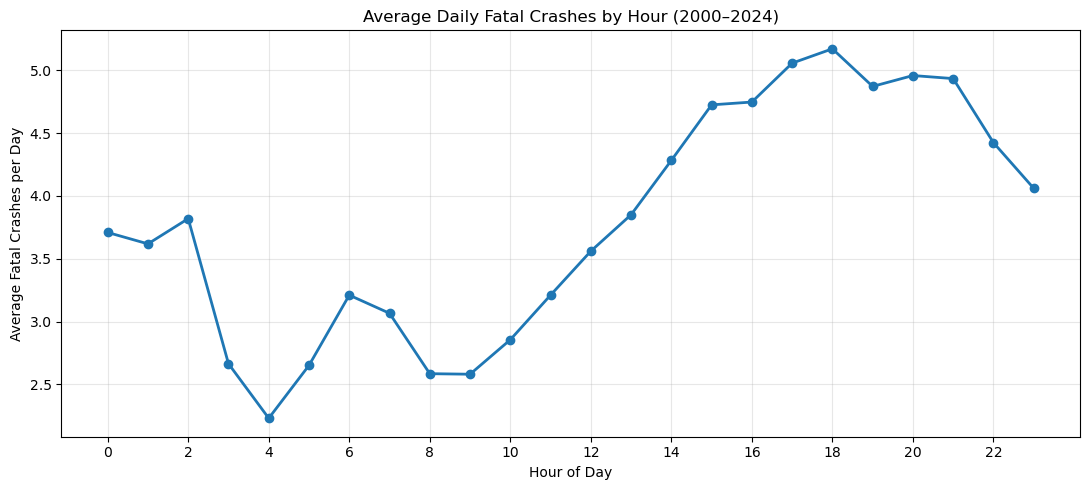

Peak hour: 18 | Average crashes per day: 5.17


In [3]:
hourly = crashes.groupby('hour_clean').size().reindex(range(24), fill_value=0)
# Average per calendar day over all 25 years (including leap days).
num_days = sum(366 if calendar.isleap(y) else 365 for y in range(2000, 2025))
hourly_daily = hourly / num_days
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hourly_daily.index, hourly_daily.values, marker='o', linewidth=2)
ax.set(title='Average Daily Fatal Crashes by Hour (2000–2024)',
       xlabel='Hour of Day', ylabel='Average Fatal Crashes per Day')
ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print('Peak hour:', hourly_daily.idxmax(), '| Average crashes per day:', round(hourly_daily.max(), 2))

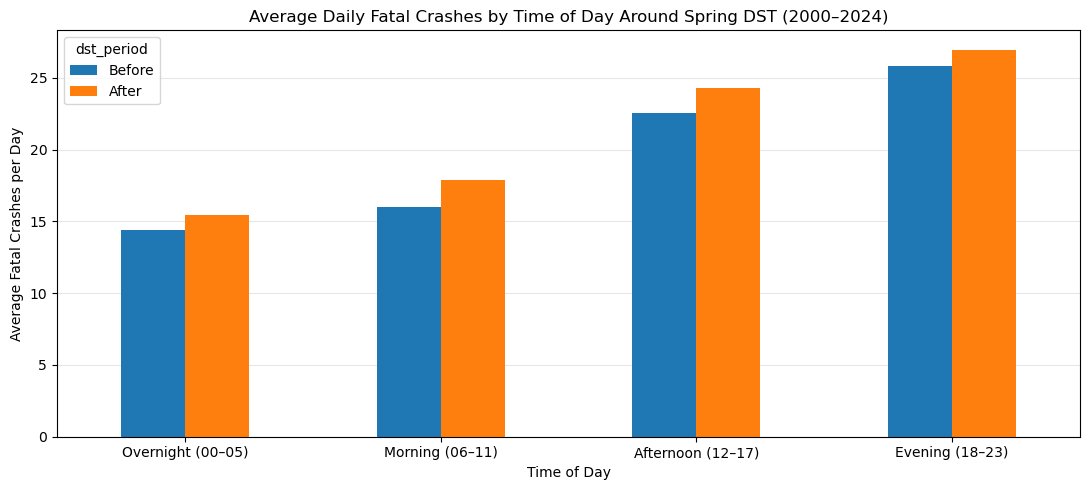

                   Before (daily)  After (daily)  Percent change
time_of_day                                                     
Overnight (00–05)           14.43          15.44            7.02
Morning (06–11)             15.97          17.85           11.73
Afternoon (12–17)           22.54          24.29            7.78
Evening (18–23)             25.79          26.95            4.50


In [4]:
period_category = (spring.groupby(['time_of_day', 'dst_period'], observed=False)
                   .size().unstack(fill_value=0).reindex(labels))
period_category_daily = period_category / DAYS_PER_PERIOD
ax = period_category_daily[['Before', 'After']].plot(kind='bar', figsize=(11, 5), rot=0)
ax.set(title='Average Daily Fatal Crashes by Time of Day Around Spring DST (2000–2024)',
       xlabel='Time of Day', ylabel='Average Fatal Crashes per Day')
ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
category_change = 100 * (period_category_daily['After'] / period_category_daily['Before'] - 1)
print(pd.DataFrame({'Before (daily)': period_category_daily['Before'],
                    'After (daily)': period_category_daily['After'],
                    'Percent change': category_change}).round(2))

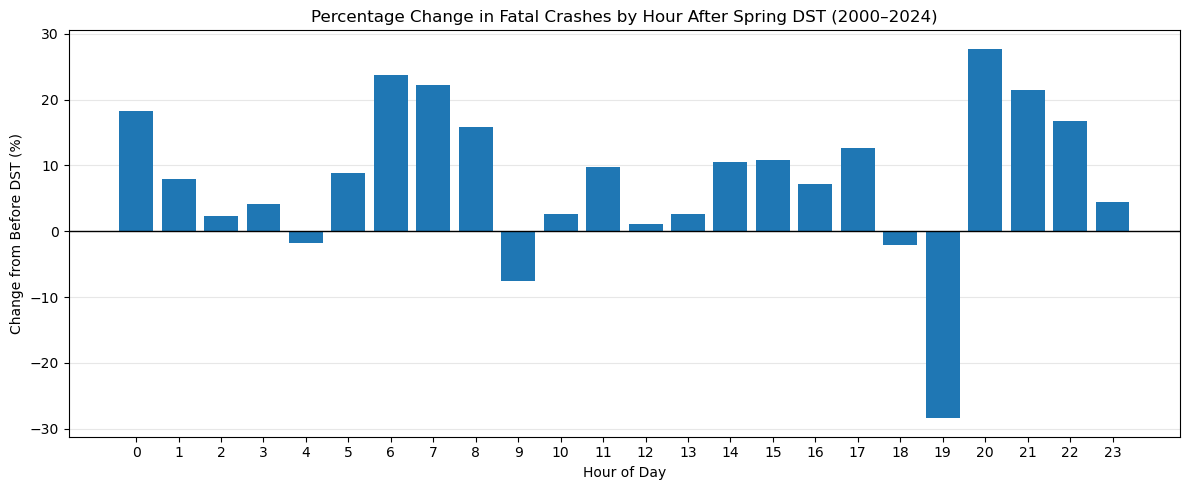

Largest increases: {20: 27.73, 6: 23.72, 7: 22.22, 21: 21.46, 0: 18.23}
Largest decreases: {19: -28.4, 9: -7.48, 18: -2.02, 4: -1.8, 12: 1.07}


In [5]:
hour_period = (spring.groupby(['hour_clean', 'dst_period']).size()
               .unstack(fill_value=0).reindex(range(24), fill_value=0))
hour_daily = hour_period / DAYS_PER_PERIOD
hour_change = 100 * (hour_daily['After'] / hour_daily['Before'].replace(0, np.nan) - 1)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hour_change.index, hour_change.values)
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Percentage Change in Fatal Crashes by Hour After Spring DST (2000–2024)',
       xlabel='Hour of Day', ylabel='Change from Before DST (%)')
ax.set_xticks(range(24)); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()
print('Largest increases:', hour_change.nlargest(5).round(2).to_dict())
print('Largest decreases:', hour_change.nsmallest(5).round(2).to_dict())

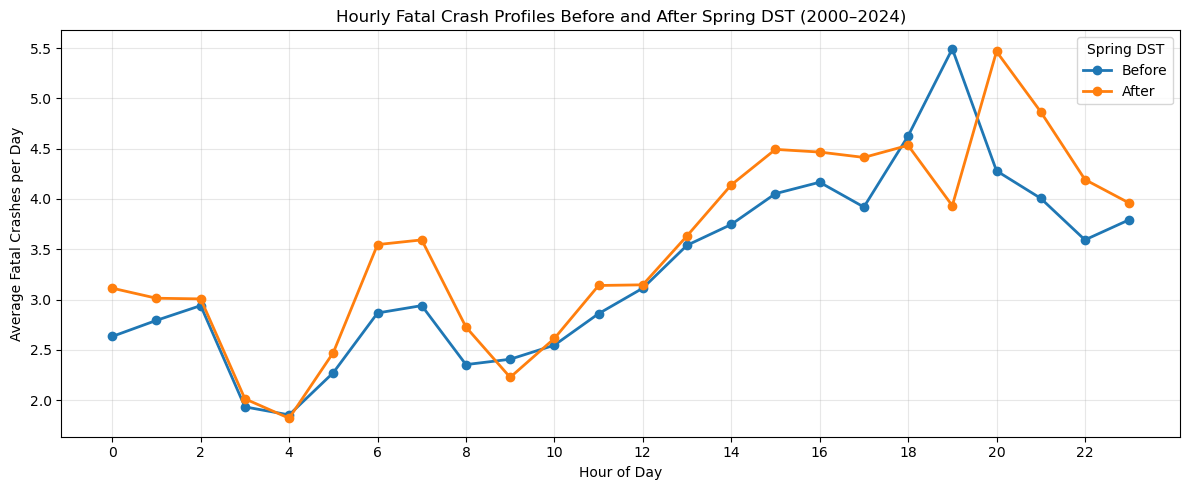

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for period in ['Before', 'After']:
    ax.plot(hour_daily.index, hour_daily[period], marker='o', linewidth=2, label=period)
ax.set(title='Hourly Fatal Crash Profiles Before and After Spring DST (2000–2024)',
       xlabel='Hour of Day', ylabel='Average Fatal Crashes per Day')
ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=0.3); ax.legend(title='Spring DST')
fig.tight_layout(); plt.show()